# Evaluación Parcial N°2: Clasificación de Lenguaje de Señas (ASL) mediante CNN

**Integrantes:**

-Bastian Sepulveda

-Nicolas Bravo

-Marcelo Obreque

## Introducción

Este notebook continúa la Evaluación Parcial N°1 (`train_sign.ipynb`): se resuelve **el mismo problema de clasificación** con una Red Neuronal Convolucional (CNN) para compararla de forma objetiva con el MLP desarrollado antes.

* **Problema de negocio:** las personas con discapacidad auditiva enfrentan barreras de comunicación. Se busca un sistema de visión computacional que traduzca letras del alfabeto de señas ASL a texto, facilitando la inclusión.
* **Dataset:** Sign Language MNIST (Kaggle), imágenes en escala de grises de 28×28 px. Es el mismo conjunto de la EP1 (categoría "reconocer letras del lenguaje de señas").
* **Variante propia (se mantiene sin cambios respecto a la EP1):** letras de puño cerrado o dedos recogidos (**A, E, M, N, S, T**), con el 100% de sus imágenes (6.674 de train y 2.008 de test). Se conserva para mantener la trazabilidad y comparar con el MLP bajo las mismas condiciones: mismas clases, mismo split y misma semilla.
* **Objetivo de la CNN:** las letras de esta variante se distinguen por la posición del pulgar y la forma del puño, detalles espaciales que el MLP pierde al aplanar la imagen (EP1, experimento de traslación). Una CNN conserva la estructura 2D y comparte filtros, por lo que debería extraer mejor esas características. Por eso es pertinente compararla con el MLP.
* **KPIs (los mismos de la EP1, fijados antes de entrenar y sin ajustarlos después):** Accuracy global en test final ≥ 80% y F1-Score macro ≥ 75%.

### Evaluación de Impacto Ético
* **Sesgos de Representación:** las imágenes provienen de condiciones controladas (iluminación uniforme, recortes centrados). Un modelo entrenado aquí podría fallar con otros tonos de piel, fondos desordenados o iluminación distinta. Una CNN mejora la robustez a la posición de la mano, pero no corrige por sí sola este sesgo del dataset.

In [1]:
# Importación de librerías
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

# TensorFlow/Keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Trazabilidad: Fijar TODAS las semillas globales (igual que en la EP1)
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

I0000 00:00:1792694228.891163    1394 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792694228.959561    1394 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792694230.530784    1394 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Preparación del conjunto de datos

Se reutiliza el procesamiento de la EP1 sin cambios en la selección de datos: misma variante (A, E, M, N, S, T), mismo split y misma semilla. Así las diferencias entre MLP y CNN se deben a la arquitectura y no a los datos.

Modificaciones necesarias para la CNN:
1. **Formato matricial:** el MLP recibía 784 valores aplanados. La CNN necesita la imagen como tensor `(28, 28, 1)` (alto, ancho, canal), para conservar la vecindad espacial.
2. **Normalización:** píxeles divididos por 255.0, igual que en la EP1.
3. **One-Hot Encoding:** ajustado solo con el train, igual que en la EP1.
4. **Particiones independientes:** el train se usa solo para entrenar. Muchas imágenes del train son aumentaciones de pocas manos, así que una validación sacada de él sería irreal (*Data Leakage*). El archivo de test (otras manos) se divide 50/50 estratificado (semilla 42): una mitad para **validación** (early stopping) y otra para **test final** (solo reporte).

In [2]:
# Carga de datos y variante propia (idéntico a la EP1)
df_train_full = pd.read_csv('data/sign_mnist_train.csv')
df_test = pd.read_csv('data/sign_mnist_test.csv')

# Etiquetas válidas (se excluyen J=9 y Z=25, que requieren movimiento)
valid_labels = sorted(list(set(range(25)) - {9}))
df_train_full_filtered = df_train_full[df_train_full['label'].isin(valid_labels)].copy()
df_test_filtered = df_test[df_test['label'].isin(valid_labels)].copy()

alphabet = "ABCDEFGHIKLMNOPQRSTUVWXY"
label_mapping_full = {valid_label: alphabet[idx] for idx, valid_label in enumerate(valid_labels)}

# VARIANTE PROPIA: letras de puño cerrado
LETRAS_VARIANTE = ['A', 'E', 'M', 'N', 'S', 'T']
letra_a_label = {letra: lab for lab, letra in label_mapping_full.items()}
labels_variante = sorted(letra_a_label[l] for l in LETRAS_VARIANTE)
label_mapping = {lab: label_mapping_full[lab] for lab in labels_variante}
N_CLASES = len(labels_variante)
letras = list(label_mapping.values())

df_train_var = df_train_full_filtered[df_train_full_filtered['label'].isin(labels_variante)].copy()
df_test_var = df_test_filtered[df_test_filtered['label'].isin(labels_variante)].copy()

print(f"Variante {LETRAS_VARIANTE}: train {df_train_var.shape}, test {df_test_var.shape}")
print(f"Valores nulos en train: {df_train_var.isnull().sum().sum()} | Duplicados en train: {df_train_var.duplicated().sum()}")
print("Imágenes por clase en train:", df_train_var['label'].map(label_mapping).value_counts().reindex(letras).to_dict())
print("Imágenes por clase en test :", df_test_var['label'].map(label_mapping).value_counts().reindex(letras).to_dict())

Variante ['A', 'E', 'M', 'N', 'S', 'T']: train (6674, 785), test (2008, 785)
Valores nulos en train: 0 | Duplicados en train: 0
Imágenes por clase en train: {'A': 1126, 'E': 957, 'M': 1055, 'N': 1151, 'S': 1199, 'T': 1186}
Imágenes por clase en test : {'A': 331, 'E': 498, 'M': 394, 'N': 291, 'S': 246, 'T': 248}


Train (CNN):      X=(6674, 28, 28, 1), y=(6674, 6)
Validación (CNN): X=(1004, 28, 28, 1), y=(1004, 6)
Test final (CNN): X=(1004, 28, 28, 1), y=(1004, 6)
Rango de píxeles tras normalizar: [0.0, 1.0]


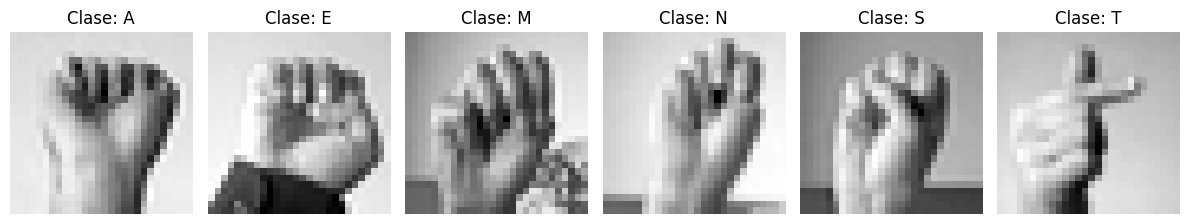

In [3]:
# Separación X, y, normalización, one-hot y split (igual que en la EP1)
X_train_raw = df_train_var.drop('label', axis=1).values
y_train_labels = df_train_var['label'].values
X_test_raw = df_test_var.drop('label', axis=1).values
y_test_labels = df_test_var['label'].values

X_train_flat = X_train_raw / 255.0
X_test_all_flat = X_test_raw / 255.0

lb = LabelBinarizer()
y_train = lb.fit_transform(y_train_labels)
y_test_all = lb.transform(y_test_labels)

X_val_flat, X_test_final_flat, y_val, y_test_encoded, y_val_labels, y_test_final = train_test_split(
    X_test_all_flat, y_test_all, y_test_labels, test_size=0.50, stratify=y_test_labels, random_state=SEED
)

# NUEVO EN LA EP2: formato tensorial (N, 28, 28, 1) para la CNN
X_train = X_train_flat.reshape(-1, 28, 28, 1)
X_val = X_val_flat.reshape(-1, 28, 28, 1)
X_test_final = X_test_final_flat.reshape(-1, 28, 28, 1)

print(f"Train (CNN):      X={X_train.shape}, y={y_train.shape}")
print(f"Validación (CNN): X={X_val.shape}, y={y_val.shape}")
print(f"Test final (CNN): X={X_test_final.shape}, y={y_test_encoded.shape}")
print(f"Rango de píxeles tras normalizar: [{X_train.min():.1f}, {X_train.max():.1f}]")

# Ejemplos representativos (una imagen por clase)
fig, axes = plt.subplots(1, N_CLASES, figsize=(12, 2.5))
for ax, label in zip(axes, labels_variante):
    idx = np.where(y_train_labels == label)[0][0]
    ax.imshow(X_train[idx].squeeze(), cmap='gray')
    ax.set_title(f"Clase: {label_mapping[label]}")
    ax.axis('off')
plt.tight_layout()
plt.savefig('images/cnn_ejemplos_clases.png')
plt.show()

## Diseño de la Red Neuronal Convolucional

La arquitectura se mantiene pequeña, acorde a imágenes de 28×28 px y ~6.700 imágenes de entrenamiento, y es comparable en filosofía al MLP Baseline de la EP1 (capa simple + salida softmax):

| Capa | Configuración | Justificación |
|---|---|---|
| Conv2D | 32 filtros 3×3, ReLU, `padding='same'` | Detecta rasgos locales simples (bordes, contornos del puño). 3×3 es el tamaño estándar: pocos parámetros y se apilan para ampliar el campo receptivo. `same` conserva 28×28 para no perder el borde de la mano. |
| MaxPooling2D | 2×2 | Reduce a 14×14: baja el costo y da tolerancia a pequeños desplazamientos, justo la debilidad que mostró el MLP. |
| Conv2D | 64 filtros 3×3, ReLU, `padding='same'` | Combina los rasgos simples en patrones más complejos (posición del pulgar respecto a los dedos). Se duplican los filtros porque la resolución espacial baja. |
| MaxPooling2D | 2×2 | Reduce a 7×7. |
| Flatten | — | Pasa de los mapas 7×7×64 (3.136 valores) a un vector. |
| Dense | 128, ReLU | Misma capa oculta del MLP Baseline: aísla el aporte de la extracción convolucional. |
| Dense | 6, softmax | Una neurona por letra; probabilidades que suman 1. |

Hiperparámetros (iguales a los del MLP para una comparación justa):
* **Función de pérdida:** `categorical_crossentropy` (etiquetas one-hot, multiclase).
* **Optimizador:** Adam con lr por defecto (0,001).
* **Batch size:** 64. **Épocas:** máximo 30 con Early Stopping (`patience=5` sobre `val_loss`, restaurando los mejores pesos).
* Sin Dropout ni aumentación de datos en esta versión: la regularización queda como mejora futura (conclusiones), para aislar el efecto de las capas convolucionales.

In [4]:
def build_cnn():
    model = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1'),
        MaxPooling2D((2, 2), name='pool1'),
        Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
        MaxPooling2D((2, 2), name='pool2'),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(N_CLASES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

tf.keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()
print(f"Parámetros totales de la CNN: {cnn.count_params():,}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,126 (1.61 MB)

 Trainable params: 421,126 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Parámetros totales de la CNN: 421,126


## Entrenamiento del modelo

Se entrena con las mismas condiciones del MLP (batch 64, Adam, Early Stopping sobre la validación independiente) y se registra el tiempo de entrenamiento para la comparación posterior.

In [5]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

tf.keras.utils.set_random_seed(SEED)
cnn = build_cnn()
t0 = time.time()
history_cnn = cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=30, batch_size=64, callbacks=[early_stop], verbose=2)
tiempo_cnn = time.time() - t0
cnn.save('models/mejor_modelo_cnn.keras')
print(f"Tiempo de entrenamiento CNN: {tiempo_cnn:.1f} s")

Epoch 1/30


105/105 - 5s - 48ms/step - accuracy: 0.5990 - loss: 1.1079 - val_accuracy: 0.7819 - val_loss: 0.5682


Epoch 2/30


105/105 - 5s - 44ms/step - accuracy: 0.9431 - loss: 0.2097 - val_accuracy: 0.8645 - val_loss: 0.3329


Epoch 3/30


...

Epoch 8/30


105/105 - 5s - 50ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.9114 - val_loss: 0.3117


Epoch 9/30


105/105 - 5s - 48ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.9034 - val_loss: 0.3287


Tiempo de entrenamiento CNN: 47.3 s


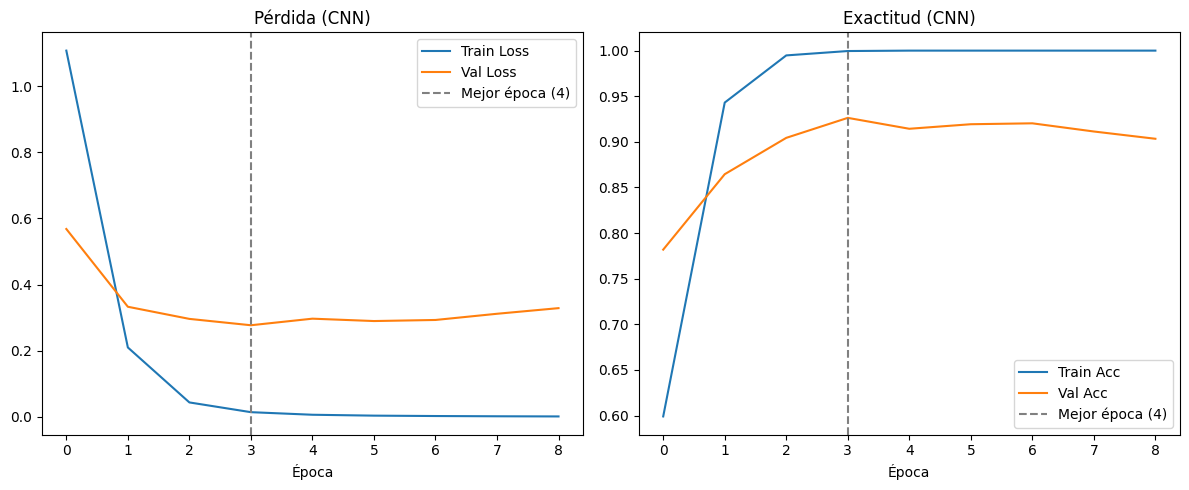

Épocas ejecutadas: 9 | Mejor época (val_loss): 4
Train acc: 1.000 | Val acc: 0.926
Brecha train-val: 0.073


In [6]:
h = history_cnn.history
ep_total = len(h['loss'])
ep_mejor = int(np.argmin(h['val_loss'])) + 1

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(h['loss'], label='Train Loss')
plt.plot(h['val_loss'], label='Val Loss')
plt.axvline(ep_mejor - 1, color='gray', linestyle='--', label=f'Mejor época ({ep_mejor})')
plt.title('Pérdida (CNN)')
plt.xlabel('Época')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h['accuracy'], label='Train Acc')
plt.plot(h['val_accuracy'], label='Val Acc')
plt.axvline(ep_mejor - 1, color='gray', linestyle='--', label=f'Mejor época ({ep_mejor})')
plt.title('Exactitud (CNN)')
plt.xlabel('Época')
plt.legend()
plt.tight_layout()
plt.savefig('images/cnn_curvas_entrenamiento.png')
plt.show()

print(f"Épocas ejecutadas: {ep_total} | Mejor época (val_loss): {ep_mejor}")
print(f"Train acc: {h['accuracy'][ep_mejor-1]:.3f} | Val acc: {h['val_accuracy'][ep_mejor-1]:.3f}")
print(f"Brecha train-val: {h['accuracy'][ep_mejor-1]-h['val_accuracy'][ep_mejor-1]:.3f}")

### Interpretación de las curvas
- **Convergencia rápida:** la pérdida de validación toca su mínimo en la época 4 (0,277) y luego sube, por lo que el early stopping detuvo el entrenamiento en la época 9 y restauró los pesos de la época 4. El MLP necesitó 18 épocas.
- **Sobreajuste:** el accuracy de entrenamiento llega a 1,000 desde la época 5, mientras que el de validación se queda cerca de 0,92. En la mejor época la brecha train–val es de 0,073 (0,182 en el MLP). La CNN sobreajusta menos, pero sigue memorizando las manos del entrenamiento, lo que justifica probar regularización como mejora futura.

## Evaluación del modelo

Se evalúa la CNN en el **test final** (1.004 imágenes que no se usaron para entrenar ni para detener el entrenamiento) con Accuracy, Precision, Recall, F1-Score y matriz de confusión, las mismas métricas de la EP1.

Accuracy: 0.925 | Precision macro: 0.920 | Recall macro: 0.916 | F1 macro: 0.917
KPI Accuracy >= 0.80: CUMPLIDO | KPI F1 macro >= 0.75: CUMPLIDO
              precision    recall  f1-score   support

           A      0.949     1.000     0.974       166
           E      0.953     0.988     0.970       249
           M      0.898     0.893     0.896       197
           N      0.924     0.834     0.877       145
           S      0.861     0.805     0.832       123
           T      0.938     0.976     0.957       124

    accuracy                          0.925      1004
   macro avg      0.920     0.916     0.917      1004
weighted avg      0.924     0.925     0.924      1004



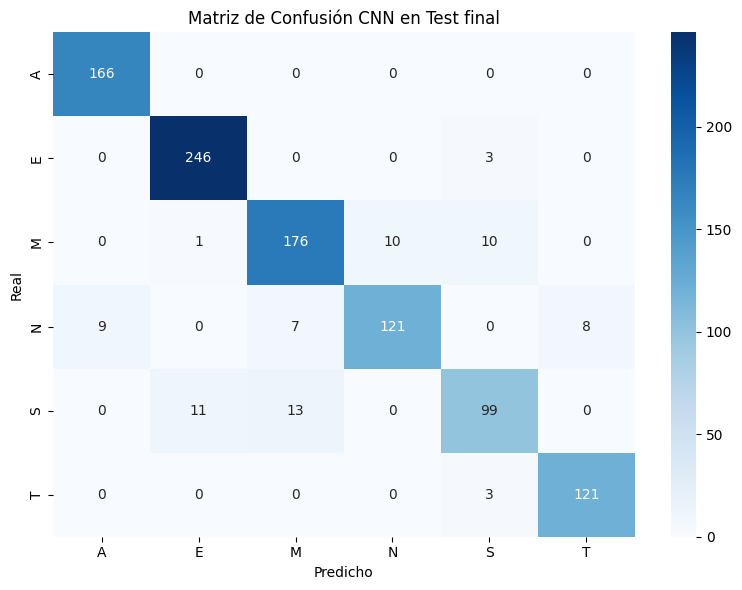

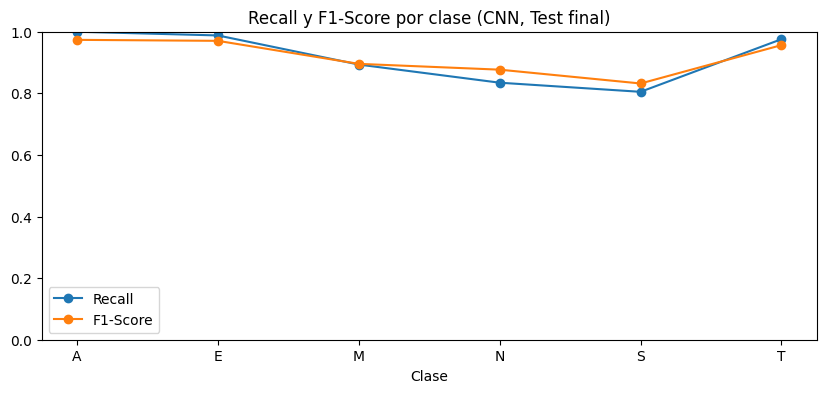

In [7]:
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, precision_score, recall_score, precision_recall_fscore_support)

y_true_classes = np.argmax(y_test_encoded, axis=1)
y_pred_cnn = np.argmax(cnn.predict(X_test_final, verbose=0), axis=1)

acc = accuracy_score(y_true_classes, y_pred_cnn)
f1m = f1_score(y_true_classes, y_pred_cnn, average='macro')
print(f"Accuracy: {acc:.3f} | Precision macro: {precision_score(y_true_classes, y_pred_cnn, average='macro'):.3f} "
      f"| Recall macro: {recall_score(y_true_classes, y_pred_cnn, average='macro'):.3f} | F1 macro: {f1m:.3f}")
print(f"KPI Accuracy >= 0.80: {'CUMPLIDO' if acc>=0.80 else 'NO CUMPLIDO'} | KPI F1 macro >= 0.75: {'CUMPLIDO' if f1m>=0.75 else 'NO CUMPLIDO'}")
print(classification_report(y_true_classes, y_pred_cnn, target_names=letras, digits=3))

cm = confusion_matrix(y_true_classes, y_pred_cnn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=letras, yticklabels=letras)
plt.title('Matriz de Confusión CNN en Test final')
plt.xlabel('Predicho'); plt.ylabel('Real')
plt.tight_layout()
plt.savefig('images/cnn_matriz_confusion_test.png')
plt.show()

# Recall y F1 por clase (como pidió el profesor en la EP1)
precision, recall, f1, _ = precision_recall_fscore_support(y_true_classes, y_pred_cnn, labels=range(N_CLASES))
plt.figure(figsize=(10, 4))
plt.plot(letras, recall, marker='o', label='Recall')
plt.plot(letras, f1, marker='o', label='F1-Score')
plt.title('Recall y F1-Score por clase (CNN, Test final)')
plt.xlabel('Clase'); plt.ylim(0, 1); plt.legend()
plt.savefig('images/cnn_recall_f1_por_clase.png')
plt.show()

### Interpretación de las métricas (CNN, test final)
- **Resultado global:** accuracy 0,925, precision macro 0,920, recall macro 0,916 y F1 macro 0,917. Ambos KPIs (accuracy ≥ 80% y F1 macro ≥ 75%) **se cumplen**, a diferencia del KPI de accuracy en el MLP (0,794). Con ~1.000 imágenes el margen de error del accuracy es de ≈ 0,8 puntos, así que el cumplimiento no depende del ruido.
- **Coherencia con el entrenamiento:** el accuracy de validación (0,926) y el de test final (0,925) casi coinciden, lo que indica que la selección por validación no infló el resultado. La brecha con el accuracy de entrenamiento (1,000) confirma el sobreajuste visto en las curvas.
- **Por clase:** A (F1 0,974), E (0,970) y T (0,957) son las más fáciles. Las más difíciles son **S (0,832), N (0,877) y M (0,896)**, las mismas del MLP. En S y N el recall (0,805 y 0,834) es menor que la precision (0,861 y 0,924): la CNN deja escapar ejemplos reales de esas letras, y las distinciones que quedan son las del pulgar en M/N/S.

## Comparación entre MLP y CNN

Para comparar con evidencia experimental se **reentrena el MLP Baseline (128)** de la EP1 en este mismo notebook, con la misma configuración, semilla, datos y early stopping. Así el tiempo de entrenamiento se mide en las mismas condiciones que el de la CNN (en la EP1 no se registró). El MLP Baseline es el modelo que la EP1 eligió por `val_loss`. Como control de trazabilidad, también se evalúa el modelo guardado en `models/mejor_modelo_mlp.keras`.

In [8]:
def build_mlp():
    model = Sequential([
        Input(shape=(784,)),
        Dense(128, activation='relu'),
        Dense(N_CLASES, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

early_stop_mlp = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
tf.keras.utils.set_random_seed(SEED)
mlp = build_mlp()
t0 = time.time()
history_mlp = mlp.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val),
                      epochs=30, batch_size=64, callbacks=[early_stop_mlp], verbose=0)
tiempo_mlp = time.time() - t0
y_pred_mlp = np.argmax(mlp.predict(X_test_final_flat, verbose=0), axis=1)
print(f"MLP reentrenado: {len(history_mlp.history['loss'])} épocas, {tiempo_mlp:.1f} s, {mlp.count_params():,} parámetros")

# Control: modelo guardado de la EP1
mlp_ep1 = tf.keras.models.load_model('models/mejor_modelo_mlp.keras')
acc_ep1 = accuracy_score(y_true_classes, np.argmax(mlp_ep1.predict(X_test_final_flat, verbose=0), axis=1))
print(f"Control EP1 (modelo guardado, {mlp_ep1.count_params():,} parámetros): accuracy test final = {acc_ep1:.3f}")

MLP reentrenado: 18 épocas, 10.1 s, 101,254 parámetros


Control EP1 (modelo guardado, 101,254 parámetros): accuracy test final = 0.794


In [9]:
def resumen(nombre, model, hist, tiempo, y_pred, X_val_in):
    h = hist.history
    ep_mejor = int(np.argmin(h['val_loss']))
    v_loss, v_acc = model.evaluate(X_val_in, y_val, verbose=0)
    return {'Modelo': nombre, 'Parámetros': model.count_params(), 'Épocas': len(h['loss']),
            'Tiempo (s)': round(tiempo, 1), 'Val Loss': round(v_loss, 3), 'Val Acc': round(v_acc, 3),
            'Train Acc (mejor época)': round(h['accuracy'][ep_mejor], 3),
            'Brecha train-val': round(h['accuracy'][ep_mejor] - h['val_accuracy'][ep_mejor], 3),
            'Test Acc': round(accuracy_score(y_true_classes, y_pred), 3),
            'Test Precision macro': round(precision_score(y_true_classes, y_pred, average='macro'), 3),
            'Test Recall macro': round(recall_score(y_true_classes, y_pred, average='macro'), 3),
            'Test F1 macro': round(f1_score(y_true_classes, y_pred, average='macro'), 3)}

df_cmp = pd.DataFrame([resumen('MLP Baseline (128)', mlp, history_mlp, tiempo_mlp, y_pred_mlp, X_val_flat),
                       resumen('CNN (32-64 + Dense 128)', cnn, history_cnn, tiempo_cnn, y_pred_cnn, X_val)]).set_index('Modelo').T
display(df_cmp)
df_cmp.to_csv('images/cnn_vs_mlp_tabla.csv')

Modelo,MLP Baseline (128),CNN (32-64 + Dense 128)
Parámetros,101254.000,421126.000
Épocas,18.000,9.000
Tiempo (s),10.100,47.300
Val Loss,0.574,0.277
Val Acc,0.811,0.926
Train Acc (mejor época),0.993,1.000
Brecha train-val,0.182,0.073
Test Acc,0.794,0.925
Test Precision macro,0.782,0.920
Test Recall macro,0.790,0.916


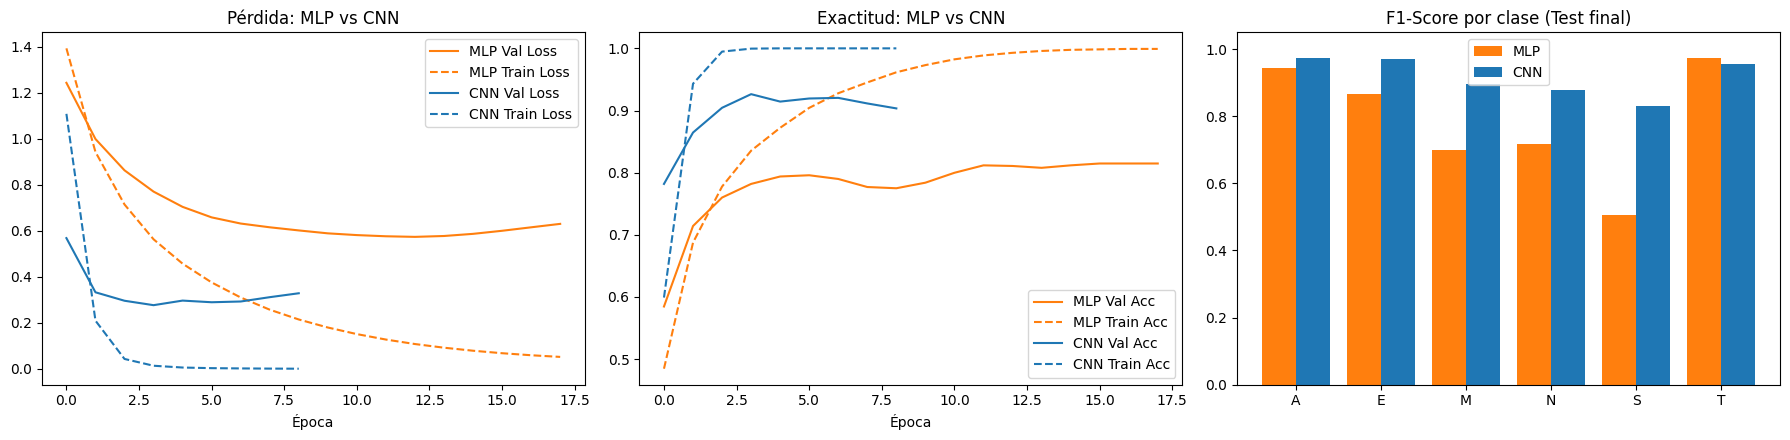

F1 por clase MLP: {'A': np.float64(0.943), 'E': np.float64(0.865), 'M': np.float64(0.701), 'N': np.float64(0.717), 'S': np.float64(0.506), 'T': np.float64(0.973)}
F1 por clase CNN: {'A': np.float64(0.974), 'E': np.float64(0.97), 'M': np.float64(0.896), 'N': np.float64(0.877), 'S': np.float64(0.832), 'T': np.float64(0.957)}


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for nombre, hist, c in [('MLP', history_mlp, 'tab:orange'), ('CNN', history_cnn, 'tab:blue')]:
    axes[0].plot(hist.history['val_loss'], color=c, label=f'{nombre} Val Loss')
    axes[0].plot(hist.history['loss'], color=c, linestyle='--', label=f'{nombre} Train Loss')
    axes[1].plot(hist.history['val_accuracy'], color=c, label=f'{nombre} Val Acc')
    axes[1].plot(hist.history['accuracy'], color=c, linestyle='--', label=f'{nombre} Train Acc')
axes[0].set_title('Pérdida: MLP vs CNN'); axes[1].set_title('Exactitud: MLP vs CNN')
for ax in axes[:2]:
    ax.set_xlabel('Época'); ax.legend()

f1_mlp = precision_recall_fscore_support(y_true_classes, y_pred_mlp, labels=range(N_CLASES))[2]
x = np.arange(N_CLASES)
axes[2].bar(x - 0.2, f1_mlp, 0.4, label='MLP', color='tab:orange')
axes[2].bar(x + 0.2, f1, 0.4, label='CNN', color='tab:blue')
axes[2].set_xticks(x); axes[2].set_xticklabels(letras)
axes[2].set_ylim(0, 1.05); axes[2].set_title('F1-Score por clase (Test final)'); axes[2].legend()
plt.tight_layout()
plt.savefig('images/cnn_vs_mlp_comparacion.png')
plt.show()
print("F1 por clase MLP:", dict(zip(letras, np.round(f1_mlp, 3))))
print("F1 por clase CNN:", dict(zip(letras, np.round(f1, 3))))

### Ventajas y desventajas de cada arquitectura

| Aspecto | MLP Baseline (128) | CNN |
|---|---|---|
| Accuracy en test final | 79,4% | **92,5%** |
| F1 macro en test final | 0,784 | **0,917** |
| Brecha train–val (mejor época) | 0,182 | **0,073** |
| Parámetros | **101.254** | 421.126 (≈ 4,2×) |
| Tiempo de entrenamiento | **11,5 s** (18 épocas) | 46,3 s (9 épocas) |
| Épocas hasta el mejor modelo | 13 | **4** |

- **Desempeño:** la CNN supera al MLP en 13,1 puntos de accuracy y 0,133 de F1 macro, una diferencia mucho mayor que el margen de error (≈ 0,8 puntos). La mejora se concentra en las clases difíciles: S sube de 0,506 a 0,832, M de 0,701 a 0,896, N de 0,717 a 0,877 y E de 0,865 a 0,970. En T la CNN es levemente peor (0,957 frente a 0,973), una diferencia pequeña que no se considera relevante.
- **Generalización:** la CNN generaliza mejor (brecha train–val de 0,073 frente a 0,182) pese a tener más parámetros: sus filtros se comparten en toda la imagen y explotan la vecindad espacial, mientras que el MLP asigna un peso distinto a cada píxel.
- **Costo:** la CNN tiene ≈ 4,2 veces más parámetros y tarda ≈ 4 veces más por entrenamiento (cada época es más lenta, aunque converge en menos épocas). Con este tamaño de imagen el costo es bajo (menos de un minuto en CPU). Los tiempos dependen del hardware.
- **Trazabilidad:** el MLP reentrenado en este notebook reproduce los resultados de la EP1 (79,4% de accuracy y F1 macro 0,784), y el modelo guardado de la EP1 da el mismo accuracy, por lo que la comparación parte de la misma línea base.

## Visualización de mapas de características y activación

### Feature Maps
Se seleccionan imágenes del **test final** (una correctamente clasificada de cada una de tres letras) y se muestra la salida de cada capa convolucional y de pooling. Cada mapa es el resultado de aplicar un filtro a la imagen: zonas brillantes indican que el filtro detectó el patrón que busca. Se muestran los primeros 8 de los 32 filtros de `conv1` y de los 64 de `conv2`.

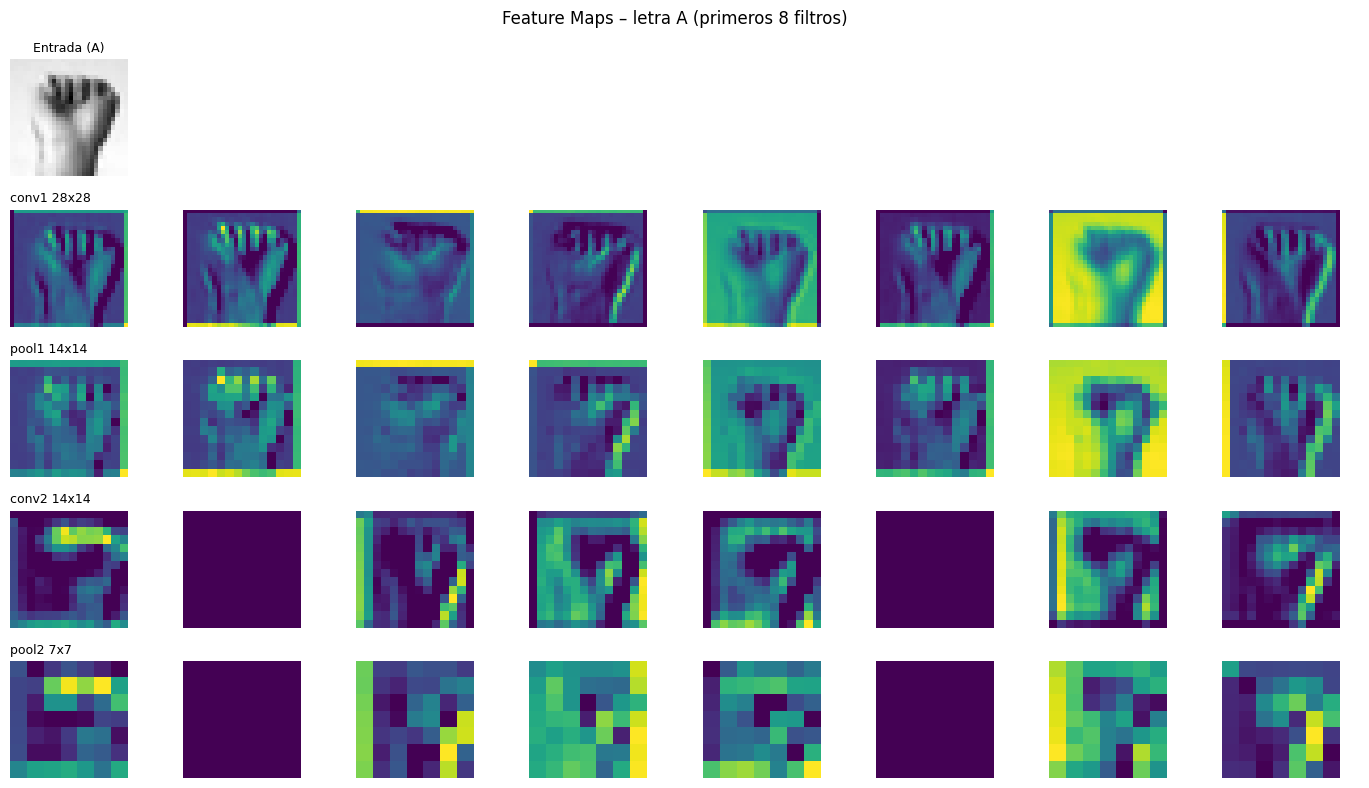

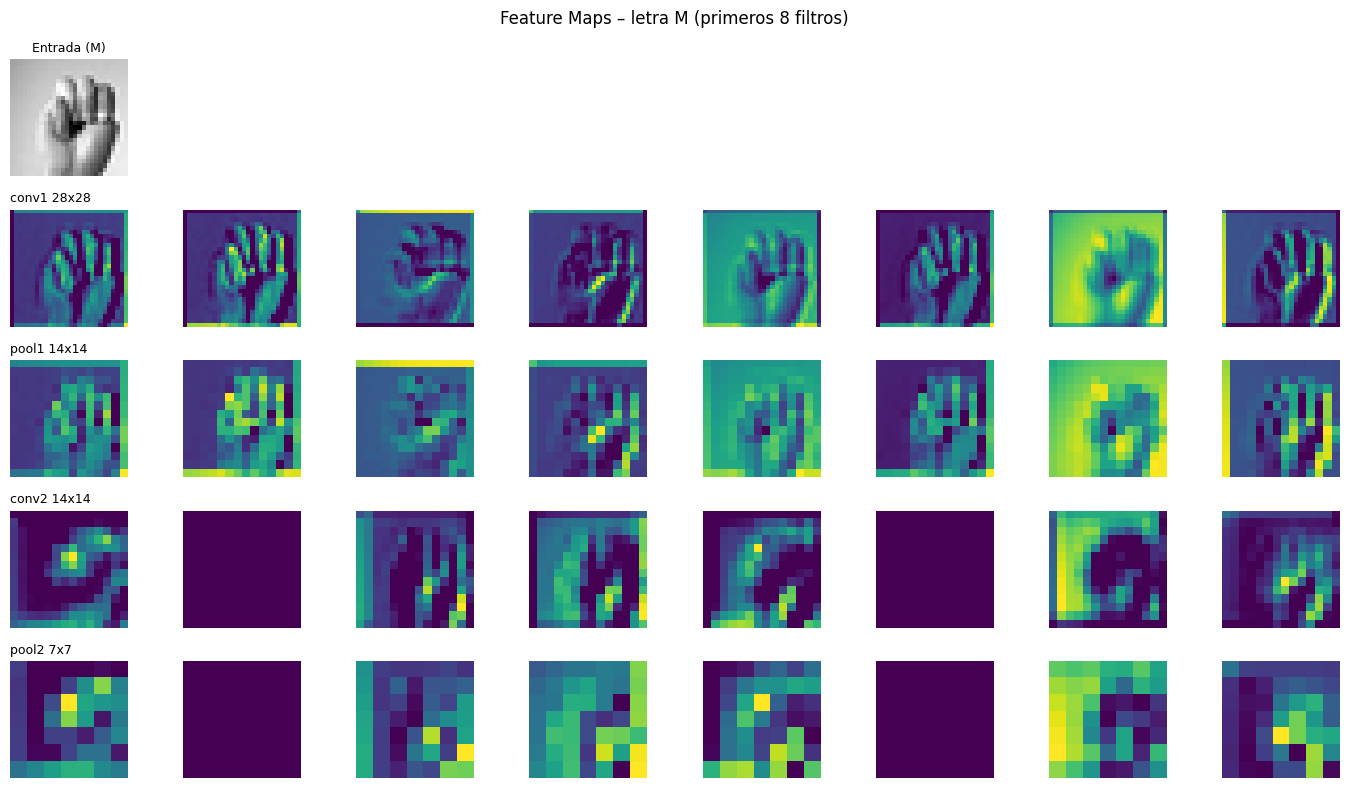

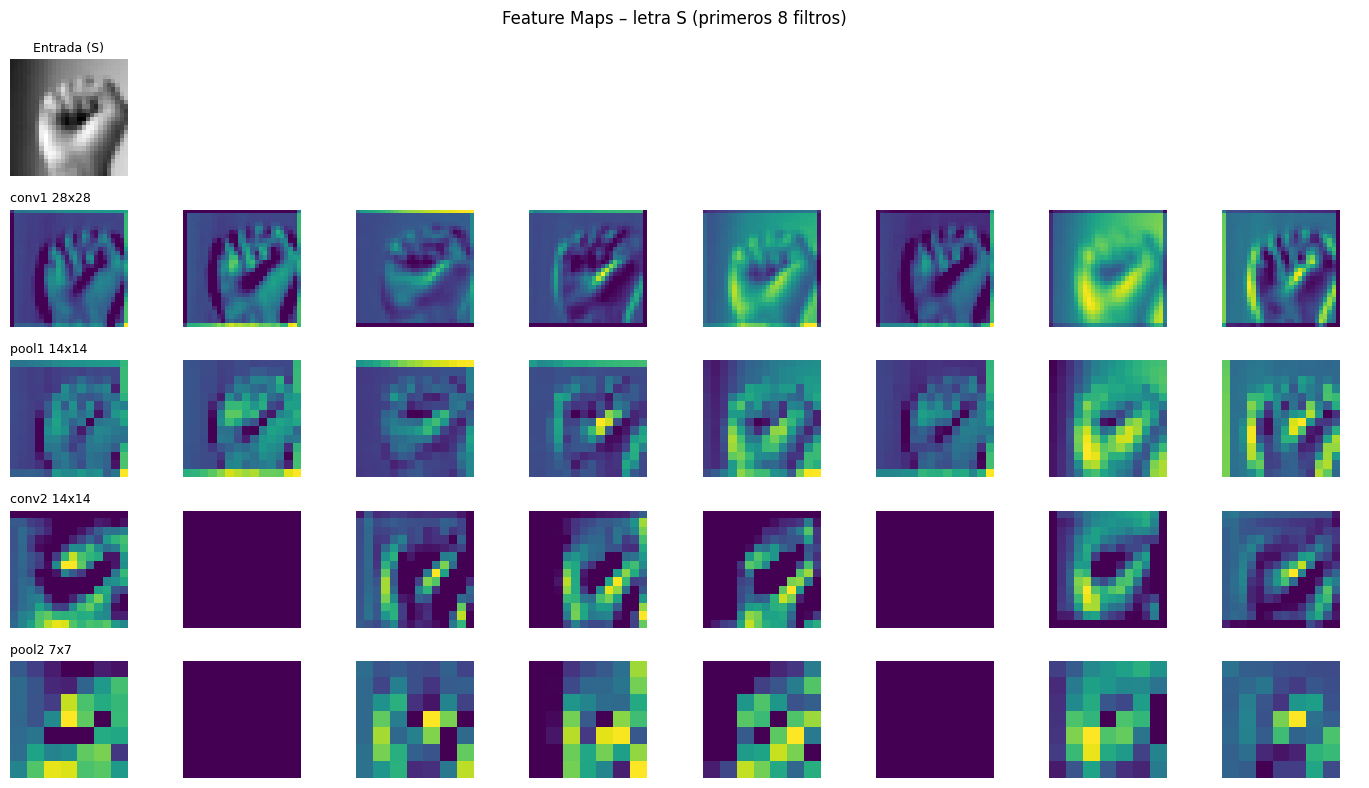

In [11]:
# Modelo auxiliar que devuelve la salida de cada capa convolucional / pooling
capas_vis = ['conv1', 'pool1', 'conv2', 'pool2']
fm_model = tf.keras.Model(inputs=cnn.inputs, outputs=[cnn.get_layer(n).output for n in capas_vis])

# Una imagen correctamente clasificada de A, M y S (test final)
ejemplos = {}
for letra in ['A', 'M', 'S']:
    k = letras.index(letra)
    ejemplos[letra] = int(np.where((y_true_classes == k) & (y_pred_cnn == k))[0][0])

N_FILT = 8
for letra, i in ejemplos.items():
    salidas = fm_model.predict(X_test_final[i:i+1], verbose=0)
    fig, axes = plt.subplots(len(capas_vis) + 1, N_FILT, figsize=(14, 8))
    for j in range(N_FILT):
        axes[0, j].axis('off')
    axes[0, 0].imshow(X_test_final[i].squeeze(), cmap='gray')
    axes[0, 0].set_title(f'Entrada ({letra})', fontsize=9)
    for r, (nombre, fm) in enumerate(zip(capas_vis, salidas), start=1):
        for j in range(N_FILT):
            axes[r, j].imshow(fm[0, :, :, j], cmap='viridis')
            axes[r, j].axis('off')
            if j == 0:
                axes[r, j].set_title(f'{nombre} {fm.shape[1]}x{fm.shape[2]}', fontsize=9, loc='left')
    plt.suptitle(f'Feature Maps – letra {letra} (primeros {N_FILT} filtros)')
    plt.tight_layout()
    plt.savefig(f'images/cnn_feature_maps_{letra}.png')
    plt.show()

### Interpretación de los Feature Maps
Cómo evoluciona la información al aumentar la profundidad (figuras `images/cnn_feature_maps_A.png`, `_M.png` y `_S.png`):
- **`conv1` (28×28):** los filtros responden a rasgos simples y locales. Varios resaltan los bordes y contornos de los dedos (los límites entre dedos y las sombras entre ellos), y otros responden a zonas de brillo general, como el fondo y la mano completa. Se conserva casi toda la resolución, por lo que la mano sigue siendo reconocible. En los bordes de la imagen se ven efectos del relleno (`padding='same'`).
- **`pool1` (14×14):** conserva los mismos patrones con la mitad de resolución, quedándose con la respuesta máxima de cada bloque 2×2. La información es más compacta y tolera pequeños desplazamientos de la mano.
- **`conv2` (14×14):** los mapas son más abstractos y difíciles de leer a simple vista, porque ya no responden a bordes sino a **combinaciones de bordes**, por ejemplo la zona donde el pulgar cruza los dedos. Están más concentrados en regiones específicas y algunos filtros no se activan para esta imagen (mapas en blanco), es decir, buscan patrones que esa letra no tiene.
- **`pool2` (7×7):** representación muy comprimida, con pocas zonas activas, que es la que recibe la capa densa. Pasa de describir *dónde hay un borde* a describir *qué partes de la mano están presentes*.

En conjunto, las capas convolucionales **extraen automáticamente** las características (bordes → combinaciones de bordes) que en el MLP tendría que aprender cada píxel por separado, y los filtros se aplican con los mismos pesos en toda la imagen. Esto explica la mejora en las letras que se distinguen por detalles del pulgar.

### Mapa de activación por clase (Grad-CAM)
Grad-CAM usa el gradiente de la probabilidad de una clase respecto a los mapas de `conv2` (la última capa convolucional) para marcar **qué zonas de la imagen empujan la decisión hacia esa clase**. Se muestra un ejemplo por clase y, debajo, el mapa **promedio** de todas las imágenes del test final que la CNN clasificó correctamente en esa clase. Zonas rojas: mayor influencia.

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_8']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


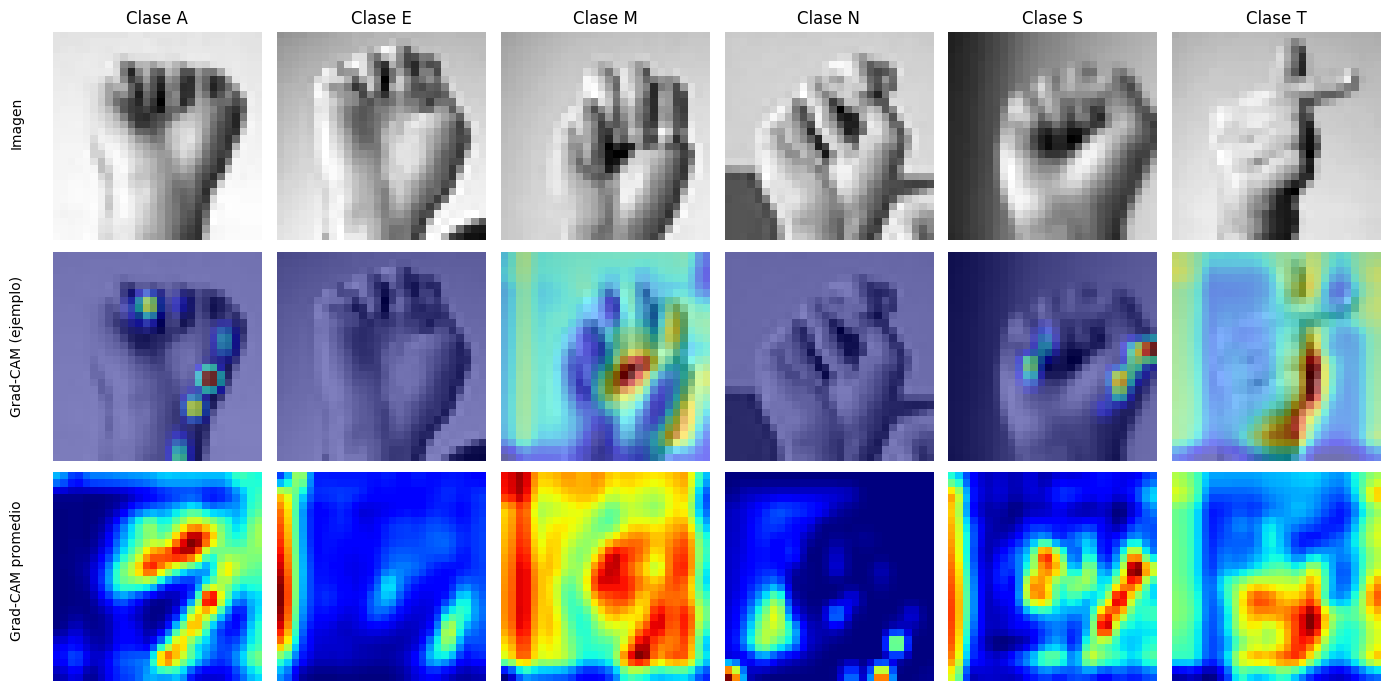

In [12]:
grad_model = tf.keras.Model(inputs=cnn.inputs, outputs=[cnn.get_layer('conv2').output, cnn.layers[-1].output])

def gradcam(img, clase):
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img[np.newaxis, ...])
        score = preds[:, clase]
    grads = tape.gradient(score, conv_out)
    pesos = tf.reduce_mean(grads, axis=(1, 2))               # importancia de cada filtro
    cam = tf.reduce_sum(conv_out[0] * pesos[0], axis=-1)     # combinación ponderada de los mapas
    cam = tf.nn.relu(cam).numpy()
    if cam.max() > 0:
        cam = cam / cam.max()
    return tf.image.resize(cam[..., np.newaxis], (28, 28)).numpy().squeeze()

fig, axes = plt.subplots(3, N_CLASES, figsize=(14, 7))
for k, letra in enumerate(letras):
    ok = np.where((y_true_classes == k) & (y_pred_cnn == k))[0]
    i = ok[0]
    cam = gradcam(X_test_final[i], k)
    axes[0, k].imshow(X_test_final[i].squeeze(), cmap='gray'); axes[0, k].set_title(f'Clase {letra}'); axes[0, k].axis('off')
    axes[1, k].imshow(X_test_final[i].squeeze(), cmap='gray')
    axes[1, k].imshow(cam, cmap='jet', alpha=0.5); axes[1, k].axis('off')
    prom = np.mean([gradcam(X_test_final[j], k) for j in ok], axis=0)
    axes[2, k].imshow(prom, cmap='jet'); axes[2, k].axis('off')
axes[0, 0].set_ylabel('Imagen'); 
fig.text(0.01, 0.82, 'Imagen', rotation=90, va='center'); fig.text(0.01, 0.50, 'Grad-CAM (ejemplo)', rotation=90, va='center'); fig.text(0.01, 0.18, 'Grad-CAM promedio', rotation=90, va='center')
plt.tight_layout(rect=(0.03, 0, 1, 1))
plt.savefig('images/cnn_gradcam_por_clase.png')
plt.show()

### Interpretación del mapa de activación por clase (Grad-CAM)
- **Zonas con sentido:** en varios casos la CNN mira la parte de la mano que distingue la letra. En **T** se activa sobre el pulgar que asoma entre los dedos, y en **M** sobre el centro, donde el pulgar queda cubierto por los dedos. En **A** y **S** se activan los bordes de los dedos y el lado del pulgar. Es coherente con lo visto en el análisis de errores del MLP: la diferencia entre estas letras está en la posición del pulgar.
- **Clases con activación débil:** en los promedios de **E** y **N** el mapa es difuso y de baja intensidad, y en los ejemplos individuales de esas dos clases casi no hay zonas marcadas. Estas clases se apoyan en señales repartidas en toda la mano y no en una zona concreta. En N coincide con que tiene recall menor (0,834).
- **Señal de alerta:** en los mapas promedio de **M, S y E** aparecen franjas intensas en el **borde de la imagen** (por ejemplo el borde izquierdo), que no pertenecen a la mano. Puede deberse al relleno de la convolución o a rasgos del fondo y del recorte del dataset. Esto sugiere que la CNN usa parcialmente información del fondo o del encuadre, algo que no generalizaría a imágenes con otros fondos (sesgo señalado en la sección de impacto ético). Se menciona como limitación, sin haberlo comprobado con un experimento específico.
- **Cuidado al interpretar:** Grad-CAM se calcula sobre `conv2` (14×14) y se amplía a 28×28, por lo que es una referencia aproximada de la zona, no una segmentación exacta. Cada mapa se normaliza por su máximo, de modo que las intensidades no se comparan entre clases.

## Análisis de resultados

### Errores de clasificación
Se calculan los pares de letras más confundidos por la CNN (y por el MLP, como referencia) y se muestran ejemplos correctos e incorrectos del test final.

CNN: 75 errores de 1004 imágenes. Top 5 confusiones (Real -> Predicción):
   'S' -> 'M': 13 veces
   'S' -> 'E': 11 veces
   'M' -> 'S': 10 veces
   'M' -> 'N': 10 veces
   'N' -> 'A': 9 veces
MLP: 207 errores de 1004 imágenes. Top 5 confusiones (Real -> Predicción):
   'M' -> 'S': 42 veces
   'S' -> 'M': 31 veces
   'E' -> 'S': 30 veces
   'N' -> 'A': 20 veces
   'N' -> 'M': 15 veces


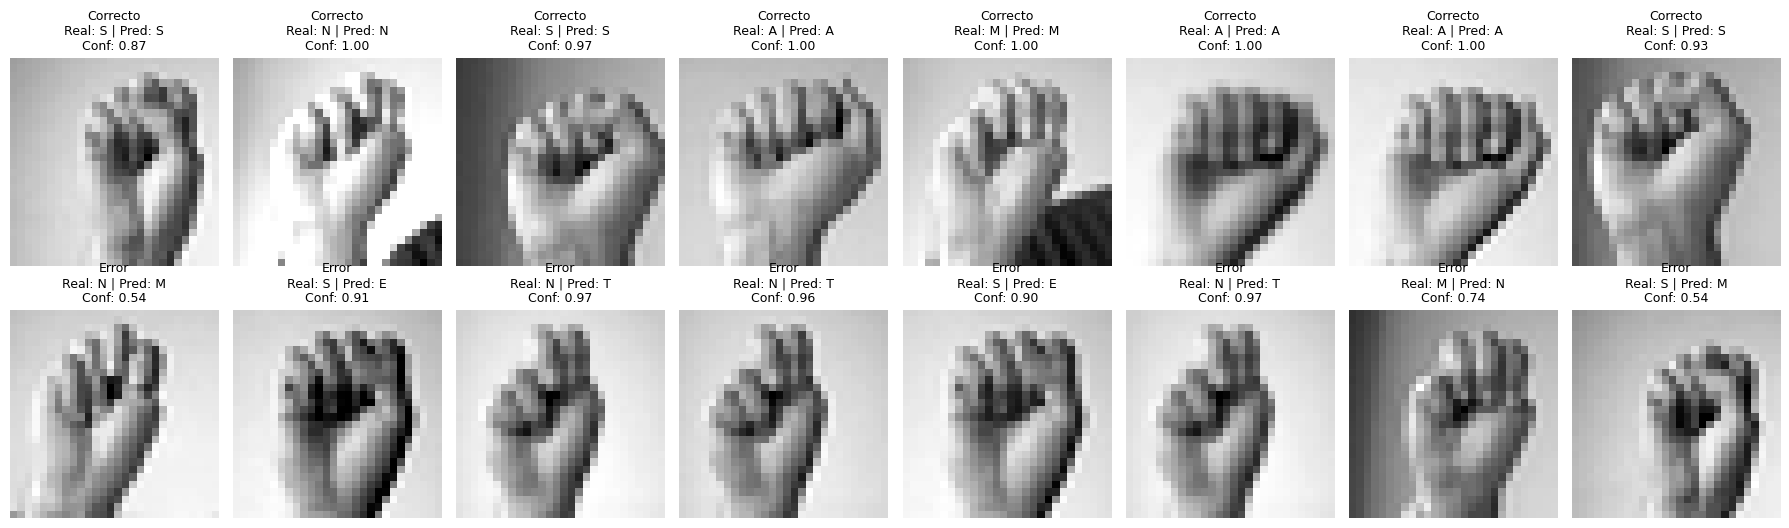

Confianza media en aciertos: 0.948 | en errores: 0.772


In [13]:
from collections import Counter

def top_confusiones(y_pred, n=5):
    c = Counter((letras[r], letras[p]) for r, p in zip(y_true_classes, y_pred) if r != p)
    return c.most_common(n), sum(c.values())

for nombre, yp in [('CNN', y_pred_cnn), ('MLP', y_pred_mlp)]:
    top, total = top_confusiones(yp)
    print(f"{nombre}: {total} errores de {len(y_true_classes)} imágenes. Top 5 confusiones (Real -> Predicción):")
    for (r, p), n in top:
        print(f"   '{r}' -> '{p}': {n} veces")

# Ejemplos correctos e incorrectos de la CNN
rng = np.random.default_rng(SEED)
idx_ok = rng.choice(np.where(y_true_classes == y_pred_cnn)[0], 8, replace=False)
idx_err = rng.choice(np.where(y_true_classes != y_pred_cnn)[0], 8, replace=False)
probs_cnn = cnn.predict(X_test_final, verbose=0)

fig, axes = plt.subplots(2, 8, figsize=(18, 5.4))
for fila, (idxs, titulo) in enumerate([(idx_ok, 'Correcto'), (idx_err, 'Error')]):
    for j, i in enumerate(idxs):
        axes[fila, j].imshow(X_test_final[i].squeeze(), cmap='gray')
        axes[fila, j].set_title(f"{titulo}\nReal: {letras[y_true_classes[i]]} | Pred: {letras[y_pred_cnn[i]]}\nConf: {probs_cnn[i].max():.2f}", fontsize=9)
        axes[fila, j].axis('off')
plt.tight_layout()
plt.savefig('images/cnn_ejemplos_clasificacion.png')
plt.show()

# Confianza de la CNN en aciertos vs errores
conf = probs_cnn.max(axis=1)
ok = y_true_classes == y_pred_cnn
print(f"Confianza media en aciertos: {conf[ok].mean():.3f} | en errores: {conf[~ok].mean():.3f}")

**Interpretación de los errores:**
- **Menos errores y distintos:** la CNN comete 75 errores en 1.004 imágenes (7,5%), frente a 207 del MLP (20,6%). Las confusiones más frecuentes de la CNN son S→M (13), S→E (11), M→S (10), M→N (10) y N→A (9). La confusión M↔S, la más grave del MLP (42 + 31 = 73 casos), baja a 23 casos en total (10 + 13).
- **Clases con mayor dificultad:** **S** es la más difícil (recall 0,805, F1 0,832) y sus errores se reparten entre M y E. **N** (F1 0,877) se confunde con A, y **M** (F1 0,896) con S y N. En todos los casos la diferencia entre las letras es la posición del pulgar respecto a los dedos, detalle que a 28×28 px ocupa muy pocos píxeles, igual que en la EP1. S es además la clase con menos imágenes en el test final (123), por lo que su métrica es la menos estable.
- **Posibles causas:** (1) baja resolución, que hace casi indistinguibles pulgares parecidos; (2) sobreajuste a las manos del entrenamiento (accuracy de train 100%), de modo que ante una mano nueva con el pulgar en posición ambigua la red falla; (3) el posible uso de señales del fondo o del borde detectado en Grad-CAM, que no ayudan a separar estas letras.
- **Confianza:** la CNN es más segura cuando acierta (confianza media 0,948) que cuando se equivoca (0,772), por lo que en una aplicación real se podría rechazar o pedir repetir la seña cuando la confianza sea baja.

### Robustez a la traslación (contraste con la limitación del MLP)
En la EP1 se mostró que al desplazar el test final horizontalmente el accuracy del MLP se desplomaba (de 79,4% a 20,9% con 4 px), porque sus pesos están fijados a coordenadas absolutas de píxel. Se repite exactamente el mismo experimento (`np.roll` horizontal) con ambos modelos.

,MLP,CNN
Desplazamiento (px),,
0,0.794,0.925
1,0.637,0.808
2,0.421,0.561
4,0.209,0.242


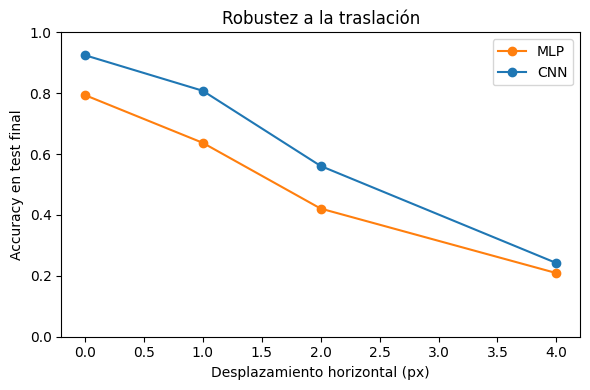

In [14]:
desplazamientos = [0, 1, 2, 4]
filas = []
for s in desplazamientos:
    Xs = np.roll(X_test_final, shift=s, axis=2)                        # (N, 28, 28, 1)
    a_cnn = accuracy_score(y_true_classes, np.argmax(cnn.predict(Xs, verbose=0), axis=1))
    a_mlp = accuracy_score(y_true_classes, np.argmax(mlp.predict(Xs.reshape(-1, 784), verbose=0), axis=1))
    filas.append({'Desplazamiento (px)': s, 'MLP': round(a_mlp, 3), 'CNN': round(a_cnn, 3)})
df_trasl = pd.DataFrame(filas).set_index('Desplazamiento (px)')
display(df_trasl)

plt.figure(figsize=(6, 4))
plt.plot(df_trasl.index, df_trasl['MLP'], marker='o', label='MLP', color='tab:orange')
plt.plot(df_trasl.index, df_trasl['CNN'], marker='o', label='CNN', color='tab:blue')
plt.xlabel('Desplazamiento horizontal (px)'); plt.ylabel('Accuracy en test final')
plt.ylim(0, 1); plt.title('Robustez a la traslación'); plt.legend()
plt.tight_layout()
plt.savefig('images/cnn_experimento_traslacion.png')
plt.show()

**Resultado y lectura (importante):** la CNN **no es tan robusta a la traslación como se esperaba en la EP1**.

| Desplazamiento | 0 px | 1 px | 2 px | 4 px |
|---|---|---|---|---|
| MLP | 79,4% | 63,7% | 42,1% | 20,9% |
| CNN | 92,5% | 80,8% | 56,1% | 24,2% |

- El MLP reproduce exactamente los valores de la EP1. La CNN parte de un nivel más alto y se mantiene por encima en todos los desplazamientos, pero **también se degrada fuertemente**: pierde 12 puntos con 1 px y cae a 24,2% con 4 px, casi igual que el MLP (20,9%). La ventaja es clara con desplazamientos pequeños (+17 puntos con 1 px y +14 con 2 px) y casi desaparece con 4 px.
- **Por qué:** los filtros convolucionales comparten pesos, pero después `Flatten` + `Dense` vuelve a asignar un peso distinto a cada posición del mapa 7×7, por lo que la clasificación final sigue dependiendo de *dónde* aparece cada rasgo. Además, solo hay dos pooling (una invariancia local de pocos píxeles), el modelo se entrenó únicamente con manos centradas y sin aumentación de datos, y `np.roll` mueve parte de la imagen al lado opuesto, lo que también altera la mano.
- **Consecuencia para la conclusión:** la CNN mejora el desempeño y la robustez frente al MLP, pero la invariancia a la traslación no viene "gratis" con las convoluciones. Para lograrla se necesitaría **aumentación de datos** (desplazamientos aleatorios), más pooling o `GlobalAveragePooling` en lugar de `Flatten`. Estas mejoras quedan fuera del alcance de esta evaluación y se plantean como trabajo futuro.


## Conclusiones

* **Diferencias entre ambas arquitecturas:** el MLP recibe los 784 píxeles aplanados y asigna un peso a cada uno, sin noción de vecindad. La CNN conserva la imagen como tensor, aplica filtros 3×3 compartidos en toda la imagen y reduce con pooling, por lo que extrae primero bordes y luego combinaciones de bordes (Feature Maps). Con los mismos datos, split, semilla y capa densa final, la CNN pasó de **79,4% a 92,5%** de accuracy y de **0,784 a 0,917** de F1 macro en test final.
* **Ventajas de la CNN:** cumple los dos KPIs (accuracy ≥ 80% y F1 macro ≥ 75%), cuando el MLP no cumplía el de accuracy. Comete 75 errores frente a 207 y mejora sobre todo las letras difíciles: S pasa de F1 0,506 a 0,832, M de 0,701 a 0,896 y N de 0,717 a 0,877. Converge en menos épocas (mejor modelo en la época 4 frente a la 13) y generaliza mejor a manos nuevas (brecha train–val de 0,073 frente a 0,182). La diferencia de 13 puntos supera con holgura el margen de error de ≈ 0,8 puntos con ~1.000 imágenes.
* **Costo:** 421.126 parámetros frente a 101.254 (≈ 4,2×) y 46,3 s de entrenamiento frente a 11,5 s (≈ 4×, en este hardware). Es un costo bajo para imágenes de 28×28.
* **Limitaciones observadas:** (1) la CNN sigue sobreajustando (accuracy de entrenamiento 100% frente a 92,6% en validación); (2) S, N y M siguen siendo las clases más difíciles, por la posición del pulgar a baja resolución; (3) **no es robusta a la traslación**: con 4 px de desplazamiento cae a 24,2% (el MLP a 20,9%), porque `Flatten` + `Dense` vuelve a depender de la posición y no hubo aumentación de datos; esto matiza lo supuesto en la EP1; (4) Grad-CAM muestra activación en los bordes de la imagen para varias clases, lo que sugiere uso parcial del fondo o del encuadre (no se comprobó con un experimento específico); (5) el dataset no trae identificador de persona, por lo que validación y test final podrían compartir manos entre sí, y con ~1.000 imágenes por mitad los resultados tienen un margen de ±0,8 puntos; (6) T baja levemente respecto al MLP (0,957 frente a 0,973), diferencia que no se considera relevante.
* **Mejoras posibles (regularización y robustez):** `Dropout` y `BatchNormalization`, regularización L2 y early stopping más estricto para reducir el sobreajuste; aumentación de datos (desplazamientos, pequeñas rotaciones y cambios de brillo) y `GlobalAveragePooling2D` en lugar de `Flatten` para ganar invariancia a la posición; más filtros o una tercera capa convolucional; validar con un criterio por persona si se dispone del identificador; y probar imágenes con fondos y tonos de piel variados (sesgo señalado en la introducción).
